<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 1: upload the file into Colab
from google.colab import files
files.upload()   # pick student-mat.csv

Saving student-mat.csv to student-mat.csv


{'student-mat.csv': b'school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3\n"GP";"F";18;"U";"GT3";"A";4;4;"at_home";"teacher";"course";"mother";2;2;0;"yes";"no";"no";"no";"yes";"yes";"no";"no";4;3;4;1;1;3;6;"5";"6";6\n"GP";"F";17;"U";"GT3";"T";1;1;"at_home";"other";"course";"father";1;2;0;"no";"yes";"no";"no";"no";"yes";"yes";"no";5;3;3;1;1;3;4;"5";"5";6\n"GP";"F";15;"U";"LE3";"T";1;1;"at_home";"other";"other";"mother";1;2;3;"yes";"no";"yes";"no";"yes";"yes";"yes";"no";4;3;2;2;3;3;10;"7";"8";10\n"GP";"F";15;"U";"GT3";"T";4;2;"health";"services";"home";"mother";1;3;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";3;2;2;1;1;5;2;"15";"14";15\n"GP";"F";16;"U";"GT3";"T";3;3;"other";"other";"home";"father";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"no";"no";4;3;2;1;2;5;4;"6";"10";10\n"GP";"M";16;"U";"LE3";"T";4;3;"service

In [2]:
# Cell 2: load the data (this file uses ; as separator)
import pandas as pd
df = pd.read_csv("student-mat.csv", sep=";")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Cell 3: understand the columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [4]:
# Cell 4: summary statistics and missing values
print(df.describe())
print("Missing values:", df.isnull().sum().sum())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

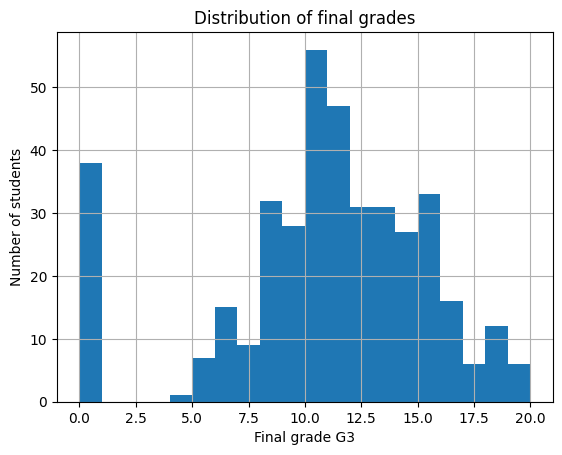

Average grade: 10.415189873417722
Students with grade 0: 38


In [5]:
# Cell 5: look at the target (final grade G3)
import matplotlib.pyplot as plt
df["G3"].hist(bins=20)
plt.xlabel("Final grade G3")
plt.ylabel("Number of students")
plt.title("Distribution of final grades")
plt.show()
print("Average grade:", df["G3"].mean())
print("Students with grade 0:", (df["G3"] == 0).sum())

In [6]:
# Cell 1: setup
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("student-mat.csv", sep=";")
df.shape

(395, 33)

In [7]:
# Cell 2: selecting
print(df["G3"].head())                       # one column
print(df[["age", "studytime", "G3"]].head()) # several columns
print(df.iloc[0])                            # first row by position
print(df.loc[0:4, ["sex", "age", "G3"]])     # rows 0-4, chosen columns

0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64
   age  studytime  G3
0   18          2   6
1   17          2   6
2   15          2  10
3   15          3  15
4   16          2  10
school             GP
sex                 F
age                18
address             U
famsize           GT3
Pstatus             A
Medu                4
Fedu                4
Mjob          at_home
Fjob          teacher
reason         course
guardian       mother
traveltime          2
studytime           2
failures            0
schoolsup         yes
famsup             no
paid               no
activities         no
nursery           yes
higher            yes
internet           no
romantic           no
famrel              4
freetime            3
goout               4
Dalc                1
Walc                1
health              3
absences            6
G1                  5
G2                  6
G3                  6
Name: 0, dtype: object
  sex  age  G3
0   F   18   6
1   F   17   6
2   F   15 

In [8]:
# Cell 3: filtering (conditions use & for AND, | for OR, each in brackets)
high_scorers = df[df["G3"] >= 15]
print("Students with G3 >= 15:", len(high_scorers))

focused = df[(df["failures"] == 0) & (df["studytime"] >= 3)]
print("No failures and studytime >= 3:", len(focused))
print("Their average G3:", focused["G3"].mean())

Students with G3 >= 15: 73
No failures and studytime >= 3: 80
Their average G3: 11.7875


In [9]:
# Cell 4: sorting
top10 = df.sort_values("G3", ascending=False)[["sex", "age", "studytime", "absences", "G3"]].head(10)
top10

,sex,age,studytime,absences,G3
47,M,16,4,4,20
286,F,18,3,5,19
374,F,18,3,0,19
110,M,15,1,6,19
8,M,15,2,0,19
113,M,15,1,10,19
91,F,15,1,4,18
42,M,15,2,2,18
36,M,15,3,2,18
104,M,15,2,0,18


In [10]:
# Cell 5: counting categories
print(df["sex"].value_counts())
print(df["school"].value_counts())
print(df["studytime"].value_counts().sort_index())

sex
F    208
M    187
Name: count, dtype: int64
school
GP    349
MS     46
Name: count, dtype: int64
studytime
1    105
2    198
3     65
4     27
Name: count, dtype: int64


In [11]:
# Cell 6: groupby, the most useful pandas tool
print(df.groupby("studytime")["G3"].mean())
print(df.groupby("sex")["G3"].mean())
print(df.groupby("failures")["G3"].agg(["count", "mean"]))

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64
sex
F     9.966346
M    10.914439
Name: G3, dtype: float64
          count       mean
failures                  
0           312  11.253205
1            50   8.120000
2            17   6.235294
3            16   5.687500


In [12]:
# Cell 7: creating a new column (pass = final grade of 10 or more)
df["passed"] = (df["G3"] >= 10).astype(int)
print(df["passed"].value_counts())
print("Pass rate:", df["passed"].mean())

passed
1    265
0    130
Name: count, dtype: int64
Pass rate: 0.6708860759493671


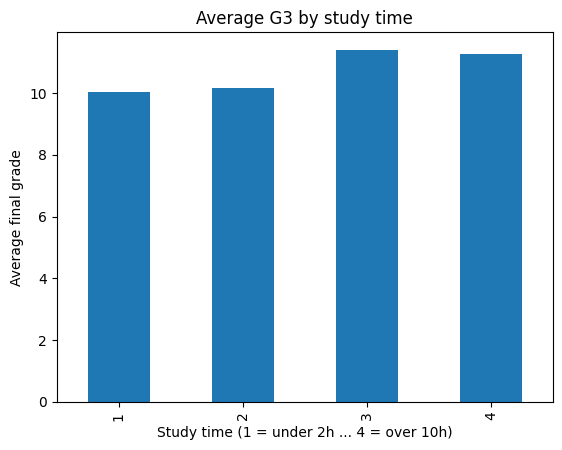

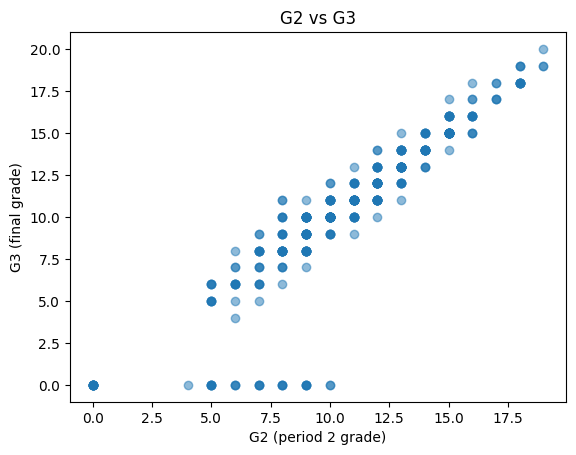

In [13]:
# Cell 8: two plots
df.groupby("studytime")["G3"].mean().plot(kind="bar")
plt.xlabel("Study time (1 = under 2h ... 4 = over 10h)")
plt.ylabel("Average final grade")
plt.title("Average G3 by study time")
plt.show()

plt.scatter(df["G2"], df["G3"], alpha=0.5)
plt.xlabel("G2 (period 2 grade)")
plt.ylabel("G3 (final grade)")
plt.title("G2 vs G3")
plt.show()

In [14]:
# Cell 9: a first look at correlation with the final grade
cols = ["G1", "G2", "G3", "studytime", "failures", "absences", "age"]
df[cols].corr()["G3"].sort_values(ascending=False)

,G3
G3,1.000000
G2,0.904868
G1,0.801468
studytime,0.097820
absences,0.034247
age,-0.161579
failures,-0.360415


In [15]:
# Cell 1: arrays, shape, data type
import numpy as np

a = np.array([1, 2, 3, 4, 5])
b = np.array([[1, 2, 3], [4, 5, 6]])

print(a, a.shape, a.dtype)
print(b)
print("b shape:", b.shape)

[1 2 3 4 5] (5,) int64
[[1 2 3]
 [4 5 6]]
b shape: (2, 3)


In [16]:
# Cell 2: creating arrays
print(np.zeros(4))
print(np.ones((2, 3)))
print(np.arange(0, 10, 2))
print(np.linspace(0, 1, 5))

np.random.seed(42)          # makes random numbers repeatable
print(np.random.randn(3))   # 3 random numbers from a normal distribution

[0. 0. 0. 0.]
[[1. 1. 1.]
 [1. 1. 1.]]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[ 0.49671415 -0.1382643   0.64768854]


In [17]:
# Cell 3: indexing and slicing
m = np.array([[10, 20, 30],
              [40, 50, 60],
              [70, 80, 90]])

print(m[0, 1])      # row 0, column 1 -> 20
print(m[:, 0])      # whole first column
print(m[1, :])      # whole second row
print(m[:2, 1:])    # top two rows, last two columns

20
[10 40 70]
[40 50 60]
[[20 30]
 [50 60]]


In [18]:
# Cell 4: vectorised operations vs loops
a = np.array([1, 2, 3, 4, 5])
print(a * 2)
print(a + 10)
print(a ** 2)
print(a + a)

# the slow way (a loop) gives the same answer
doubled = []
for x in a:
    doubled.append(x * 2)
print(doubled)

[ 2  4  6  8 10]
[11 12 13 14 15]
[ 1  4  9 16 25]
[ 2  4  6  8 10]
[np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10)]


In [19]:
# Cell 5: statistics and axis
grades = np.array([[12, 14, 15],
                   [8, 9, 10],
                   [16, 17, 18]])

print("Mean:", grades.mean())
print("Std:", grades.std())
print("Max:", grades.max(), "Min:", grades.min())
print("Mean of each column:", grades.mean(axis=0))   # axis=0 -> down the rows
print("Mean of each row:", grades.mean(axis=1))      # axis=1 -> across the columns

Mean: 13.222222222222221
Std: 3.424674446093876
Max: 18 Min: 8
Mean of each column: [12.         13.33333333 14.33333333]
Mean of each row: [13.66666667  9.         17.        ]


In [20]:
# Cell 6: dot product and matrix multiplication (the heart of ML)
# one student: studytime, failures, absences
student = np.array([3, 0, 6])
weights = np.array([1.5, -2.0, -0.1])
bias = 8

print("Prediction:", np.dot(student, weights) + bias)   # 11.9

# three students at once
students = np.array([[3, 0, 6],
                     [1, 2, 10],
                     [4, 0, 0]])
print("Predictions:", students @ weights + bias)        # [11.9  4.5  14.]

Prediction: 11.9
Predictions: [11.9  4.5 14. ]


In [21]:
# Cell 7: boolean masks and normalisation
scores = np.array([4, 9, 12, 15, 7, 18, 10])

print(scores >= 10)                    # True/False for each
print(scores[scores >= 10])            # only the passing scores
print("Pass count:", (scores >= 10).sum())

# z-score normalisation: mean 0, std 1
z = (scores - scores.mean()) / scores.std()
print(z.round(2))
print("New mean:", z.mean().round(4), "New std:", z.std().round(4))

[False False  True  True False  True  True]
[12 15 18 10]
Pass count: 4
[-1.53 -0.39  0.29  0.97 -0.84  1.66 -0.16]
New mean: 0.0 New std: 1.0


In [22]:
# Cell 8: from your DataFrame to NumPy
import pandas as pd
df = pd.read_csv("student-mat.csv", sep=";")   # upload the file again if Colab restarted

X = df[["studytime", "failures", "absences", "G1"]].values
y = df["G3"].values

print("X shape:", X.shape)    # (395, 4)
print("y shape:", y.shape)    # (395,)

# add a column of ones so the bias is learned like any other weight
X_b = np.c_[np.ones(len(X)), X]
print("X_b shape:", X_b.shape)   # (395, 5)

X shape: (395, 4)
y shape: (395,)
X_b shape: (395, 5)


In [23]:
# Cell 9: your first prediction and error metrics
np.random.seed(42)
w = np.random.randn(X_b.shape[1]) * 0.1   # 5 random weights

y_pred = X_b @ w
errors = y_pred - y

mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(errors))

print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("MAE :", round(mae, 2))

MSE : 118.02
RMSE: 10.86
MAE : 9.77
